In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import boxcox

In [2]:
CSV_PATH = "cyber_threats_dataset.csv"
df = pd.read_csv(CSV_PATH)


In [3]:
print("Перші 5 рядків:")
print(df.head())


Перші 5 рядків:
                          Timestamp Protocol Flag Packet  Sender ID  \
0         2025-01-01T00:00:00+00:00      TCP  SYN   SMTP      285.0   
1  2025-01-03T09:24:25.321608+00:00      TCP  SYN   HTTP      190.0   
2  2025-01-05T18:48:50.643216+00:00      TCP  SYN   SMTP      941.0   
3  2025-01-08T04:13:15.964824+00:00      UDP  ACK    FTP      321.0   
4  2025-01-10T13:37:41.286432+00:00      TCP  NaN    FTP       74.0   

   Receiver ID Source IP Address Source Country Destination IP Address  \
0        810.0               NaN         Sweden          50.20.158.136   
1        101.0     164.255.59.58         Mexico                    NaN   
2          6.0     59.193.228.69      Singapore         29.123.203.111   
3        331.0     172.36.239.85      Argentina           178.87.57.15   
4        766.0    174.131.29.180            NaN          142.5.243.242   

  Destination Country  Source Port  Destination Port  Packet Size  \
0              Canada      36248.0         

In [4]:
missing_values = df.isnull().sum()
print("Кількість пропущених значень у кожній колонці:")
print(missing_values)


Кількість пропущених значень у кожній колонці:
Timestamp                  2
Protocol                  11
Flag                      11
Packet                    19
Sender ID                 24
Receiver ID               11
Source IP Address         11
Source Country            19
Destination IP Address    13
Destination Country       12
Source Port               19
Destination Port          21
Packet Size               25
Target Variable           16
dtype: int64


In [5]:
missing_percentage = df.isnull().mean() * 100
print("Відносна кількість пропущених значень (%):")
print(missing_percentage)


Відносна кількість пропущених значень (%):
Timestamp                  0.925926
Protocol                   5.092593
Flag                       5.092593
Packet                     8.796296
Sender ID                 11.111111
Receiver ID                5.092593
Source IP Address          5.092593
Source Country             8.796296
Destination IP Address     6.018519
Destination Country        5.555556
Source Port                8.796296
Destination Port           9.722222
Packet Size               11.574074
Target Variable            7.407407
dtype: float64


In [ ]:
print("Опис вибірки для виявлення аномалій та некоректних даних:")
print(df.describe(include="all"))


Опис вибірки для виявлення аномалій та некоректних даних:
                               Timestamp Protocol Flag Packet    Sender ID  \
count                                214      205  205    197   192.000000   
unique                               198        2    4      6          NaN   
top     2025-10-17T10:15:03.914573+00:00      TCP  SYN    FTP          NaN   
freq                                   3      108   59     41          NaN   
mean                                 NaN      NaN  NaN    NaN   486.447917   
std                                  NaN      NaN  NaN    NaN   297.436865   
min                                  NaN      NaN  NaN    NaN     9.000000   
25%                                  NaN      NaN  NaN    NaN   223.750000   
50%                                  NaN      NaN  NaN    NaN   475.000000   
75%                                  NaN      NaN  NaN    NaN   741.000000   
max                                  NaN      NaN  NaN    NaN  1000.000000   

     

In [ ]:
missing_by_column = df.isna().sum()
missing_pct_by_column = df.isna().mean() * 100
missing_report = (
    pd.DataFrame({"missing_count": missing_by_column, "missing_percent": missing_pct_by_column})
    .sort_values("missing_count", ascending=False)
)
print(missing_report)

df["has_missing"] = df.isna().any(axis=1)
df["missing_count"] = df.isna().sum(axis=1)


In [8]:
df_cleaned_rows = df.dropna()
print(f"Форма таблиці після видалення рядків: {df_cleaned_rows.shape}")


Форма таблиці після видалення рядків: (74, 16)


In [9]:
dropped_columns = df.columns[df.isnull().any()].tolist()
df_cleaned_columns = df.dropna(axis=1)
print("Видалені колонки (містили хоча б один NaN):", dropped_columns)
print(f"Форма таблиці після видалення колонок: {df_cleaned_columns.shape}")


Видалені колонки (містили хоча б один NaN): ['Timestamp', 'Protocol', 'Flag', 'Packet', 'Sender ID', 'Receiver ID', 'Source IP Address', 'Source Country', 'Destination IP Address', 'Destination Country', 'Source Port', 'Destination Port', 'Packet Size', 'Target Variable']
Форма таблиці після видалення колонок: (216, 2)


In [10]:
df_filled = df.copy()
for column in df_filled.select_dtypes(include=[np.number]).columns:
    df_filled[column] = df_filled[column].fillna(df_filled[column].mean())

for column in df_filled.select_dtypes(include=["object"]).columns:
    if column == "Timestamp":
        continue
    if df_filled[column].isnull().any():
        mode_val = df_filled[column].mode(dropna=True)
        if len(mode_val) > 0:
            df_filled[column] = df_filled[column].fillna(mode_val.iloc[0])

df_filled["Packet Size"] = pd.to_numeric(df_filled["Packet Size"], errors="coerce")
df_filled["Packet Size"] = df_filled["Packet Size"].interpolate(method="linear")
df_filled = df_filled.ffill().bfill()


/tmp/ipykernel_158574/435576069.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df_filled.select_dtypes(include=["object"]).columns:


In [11]:
print(df_filled.dtypes)


Timestamp                     str
Protocol                      str
Flag                          str
Packet                        str
Sender ID                 float64
Receiver ID               float64
Source IP Address             str
Source Country                str
Destination IP Address        str
Destination Country           str
Source Port               float64
Destination Port          float64
Packet Size               float64
Target Variable               str
has_missing                  bool
missing_count               int64
dtype: object


In [12]:
df_filled["Timestamp"] = pd.to_datetime(
    df_filled["Timestamp"], utc=True, errors="coerce", format="ISO8601"
)
df_filled["ts_year"] = df_filled["Timestamp"].dt.year
df_filled["ts_month"] = df_filled["Timestamp"].dt.month
df_filled["ts_day_of_week"] = df_filled["Timestamp"].dt.dayofweek
df_filled["ts_day_of_month"] = df_filled["Timestamp"].dt.day


In [ ]:
df_processed = df_filled.copy()
df_processed.to_csv("processed_dataset.csv", index=False)
print(
    "processed_dataset.csv: після заповнення пропусків, дат і похідних колонок часу "
    "(без MinMaxScaler і Box–Cox)"
)


In [13]:
num_columns = df_filled.select_dtypes(include=[np.number]).columns
for column in num_columns:
    q_low = df_filled[column].quantile(0.01)
    q_high = df_filled[column].quantile(0.99)
    anomalies = df_filled[(df_filled[column] < q_low) | (df_filled[column] > q_high)]
    if not anomalies.empty:
        print(f"Аномальні значення у {column}:")
        print(anomalies.head())


Аномальні значення у Sender ID:
                           Timestamp Protocol Flag Packet  Sender ID  \
54  2025-05-10 03:58:47.366834+00:00      TCP  SYN   ICMP        9.0   
60  2025-05-24 12:25:19.296482+00:00      UDP  RST   HTTP     1000.0   
66  2025-06-07 20:51:51.226131+00:00      UDP  RST    SSH       13.0   
108 2025-09-16 07:57:34.733668+00:00      UDP  RST    SSH       14.0   
144 2025-12-11 10:36:46.311558+00:00      TCP  RST    SSH      998.0   

     Receiver ID Source IP Address Source Country Destination IP Address  \
54         613.0    48.150.132.223         France            60.40.64.80   
60         679.0     59.115.195.98          Japan         135.220.102.64   
66         583.0    202.139.183.52          India        187.219.113.142   
108        426.0    122.94.101.137          Japan         184.192.15.151   
144        670.0     204.19.26.150          Italy          39.169.193.52   

    Destination Country  Source Port  Destination Port  Packet Size  \
54     

In [14]:
scaler = MinMaxScaler(feature_range=(-1, 1))
df_filled["Packet Size scaled"] = scaler.fit_transform(df_filled[["Packet Size"]])


In [15]:
numeric_column = "Packet Size"
if (df_filled[numeric_column] > 0).all():
    df_filled["Packet Size boxcox"], _ = boxcox(df_filled[numeric_column])


In [16]:
print("Кодова таблиця для колонки Packet:")
print(df_filled["Packet"].value_counts())


Кодова таблиця для колонки Packet:
Packet
FTP     60
DNS     37
SSH     32
ICMP    31
SMTP    30
HTTP    26
Name: count, dtype: int64


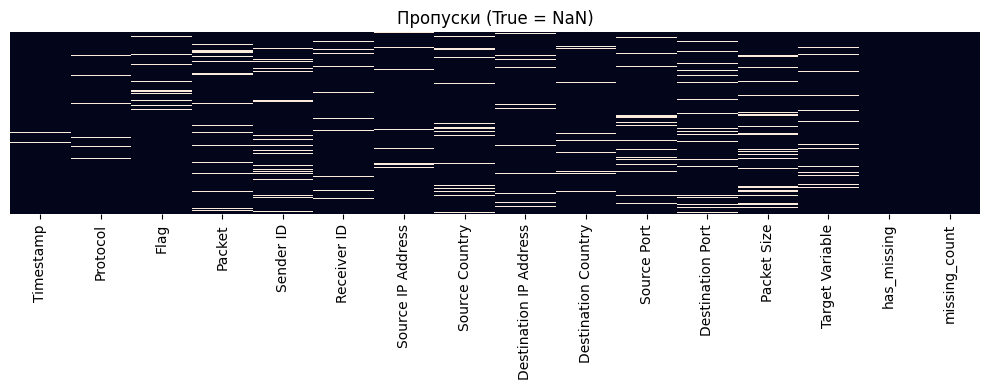

In [18]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Пропуски (True = NaN)")
plt.tight_layout()
plt.show()


In [19]:
df_cmp = pd.read_csv(CSV_PATH)
num_col = "Packet Size"
mean_f = pd.to_numeric(df_cmp[num_col], errors="coerce").fillna(pd.to_numeric(df_cmp[num_col], errors="coerce").mean())
med_f = pd.to_numeric(df_cmp[num_col], errors="coerce").fillna(pd.to_numeric(df_cmp[num_col], errors="coerce").median())
cmp = pd.DataFrame({"mean_fill": mean_f, "median_fill": med_f})
print(cmp.describe())


         mean_fill  median_fill
count   216.000000   216.000000
mean   1871.680628  1850.768519
std    1061.815675  1063.395112
min      99.000000    99.000000
25%    1053.750000  1053.750000
50%    1871.680628  1691.000000
75%    2711.000000  2711.000000
max    4094.000000  4094.000000


In [20]:
ps = pd.to_numeric(df_cmp["Packet Size"], errors="coerce")
q1 = ps.quantile(0.25)
q3 = ps.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
out_iqr = df_cmp[(ps < low) | (ps > high)]
print("Викиди за IQR (Packet Size):", len(out_iqr))


Викиди за IQR (Packet Size): 0


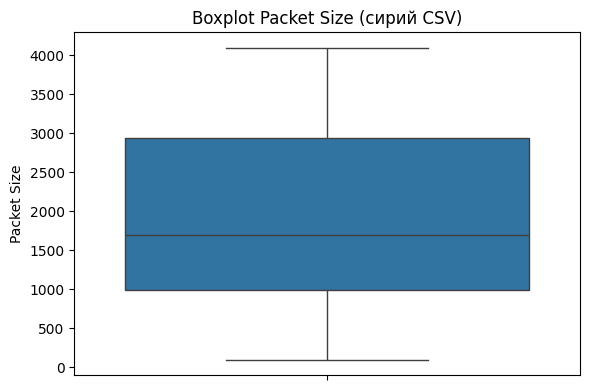

In [21]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_cmp, y=pd.to_numeric(df_cmp["Packet Size"], errors="coerce"))
plt.title("Boxplot Packet Size (сирий CSV)")
plt.tight_layout()
plt.show()


In [22]:
df_filled.to_csv("cleaned_data.csv", index=False)
print("Збережено cleaned_data.csv")


Збережено cleaned_data.csv


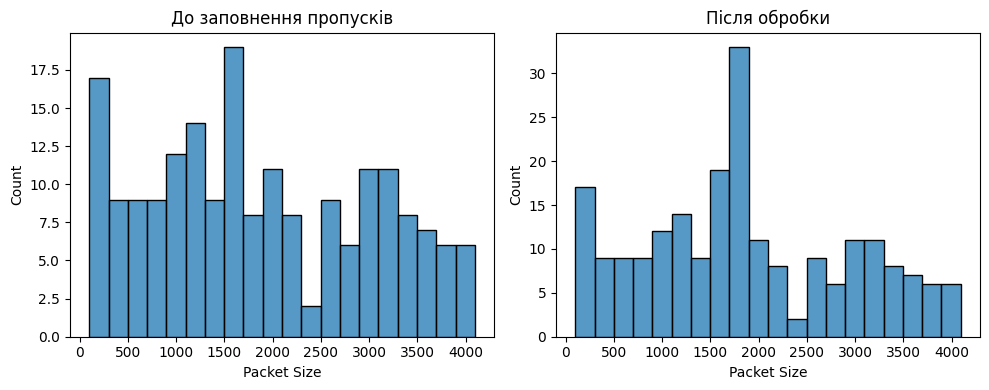

In [23]:
ps_raw = pd.to_numeric(pd.read_csv(CSV_PATH)["Packet Size"], errors="coerce")
ps_clean = pd.to_numeric(df_filled["Packet Size"], errors="coerce")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(ps_raw.dropna(), bins=20, ax=ax[0])
ax[0].set_title("До заповнення пропусків")
sns.histplot(ps_clean.dropna(), bins=20, ax=ax[1])
ax[1].set_title("Після обробки")
plt.tight_layout()
plt.show()
